# 05 — Annotate pages
These images contain only B/A IDs. The labeling website draws GT names separately.

No models.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "project.json").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pipeline_helpers as P
import json
from PIL import Image, ImageDraw, ImageFont
ROOT = P.ROOT
MODELS = P.read_json(ROOT / "models.json")
SPLITS = ["train", "val"]  # Or ["train"] / ["val"].
FORCE_RERUN = False
items = P.pages(SPLITS)
print("Pages:", len(items))


Pages: 240


Draw each prepared page and save its metadata.

In [2]:
for item in items:
    PAGE = Path(item["image_path"])
    page = Image.open(PAGE).convert("RGB")
    OUT = P.page_folder(item)
    OUT.mkdir(parents=True, exist_ok=True)
    settings = {"version":1}
    dependencies = [OUT / "bubbles_clean.json", OUT / "characters.json"]
    def save_stage(name, records):
        P.save_stage(item, name, records, settings, dependencies)
    def load_stage(name):
        return P.load_stage(item, name)
    if all(P.cached(item, name, settings, dependencies, FORCE_RERUN) for name in ['annotation.json']):
        print("Cached:", item["split"], item["sequence_id"], item["page_number"])
        continue
    bubbles = load_stage("bubbles_clean.json")
    characters = load_stage("characters.json")
    draw = ImageDraw.Draw(page)
    for records, key, color in [(bubbles, "bubble_id", "blue"), (characters, "character_id", "red")]:
        for record in records:
            label = record[key].replace("C", "A", 1)
            x1, y1, x2, y2 = record["box"]
            draw.rectangle(record["box"], outline=color, width=3)
            draw.text((x1 + 3, y1 + 3), label, fill=color, stroke_width=1, stroke_fill="white")
    page.save(OUT / "annotated_page.png")
    save_stage("annotation.json", {"image":"annotated_page.png"})


## View saved results
These cells only read saved results. They do not run models or change cached files. Training shows targets and run-wide loss history; validation shows saved predictions.

In [3]:
from pathlib import Path
import sys, importlib
view_root = Path.cwd().resolve()
if not (view_root / "project.json").is_file():
    view_root = view_root.parent
sys.path.insert(0, str(view_root))
import result_viewer as V
importlib.reload(V)
VIEW_STAGE = 'annotation'
VIEW_SPLIT = "train"  # Or "val".
VIEW_RUN = None


### 1. View a random page
Rerun this cell to choose another page with a saved result in this split.


train | seq_2032620aa4e4ac7f | page 2


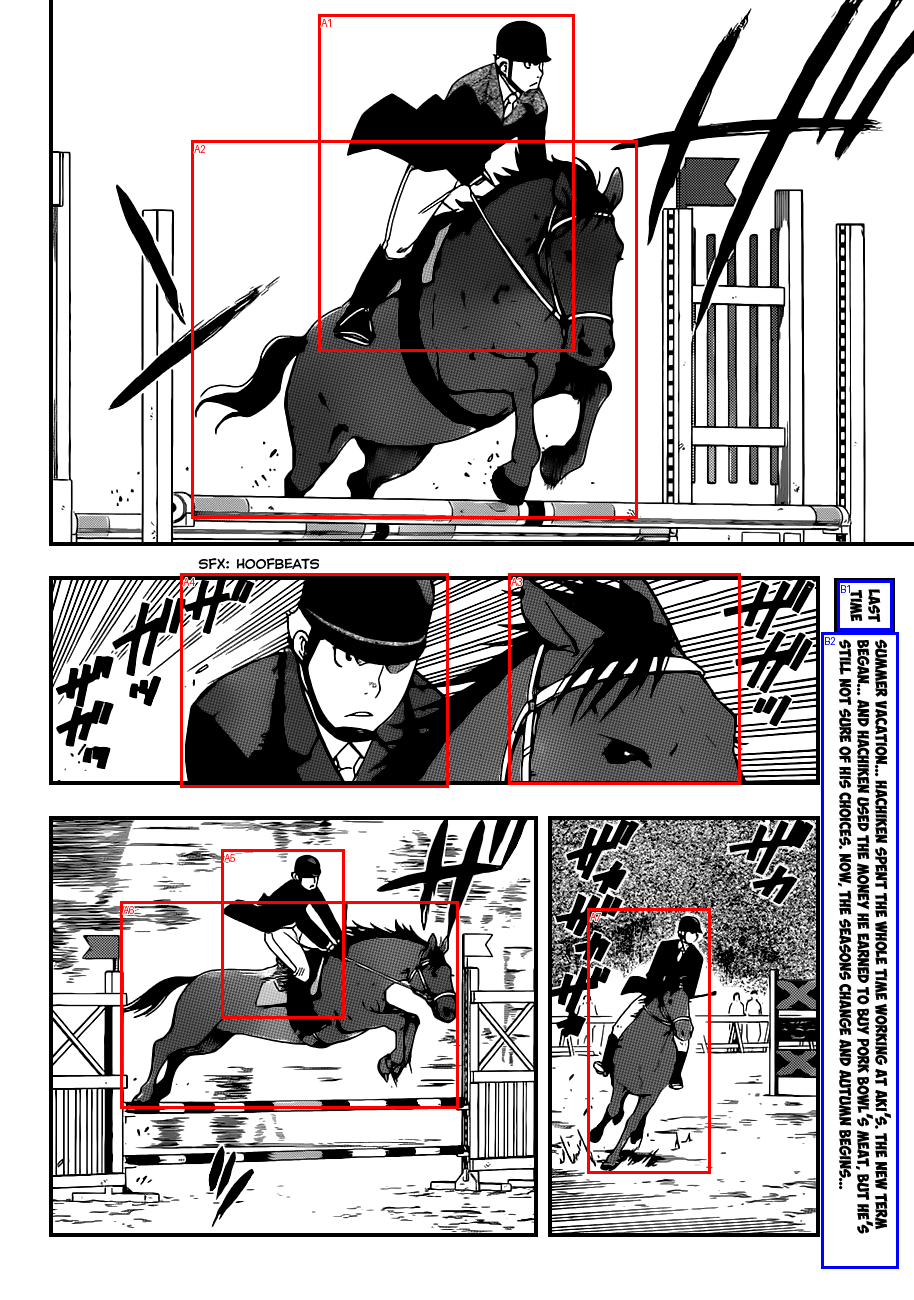

In [4]:
viewed_page = V.show_random(VIEW_STAGE, split=VIEW_SPLIT, run_folder=VIEW_RUN)


### 2. View all pages of a sequence
Enter a sequence ID, or leave it empty to use the random page’s sequence. Missing stage results are reported for each page.


train | seq_2032620aa4e4ac7f | page 1


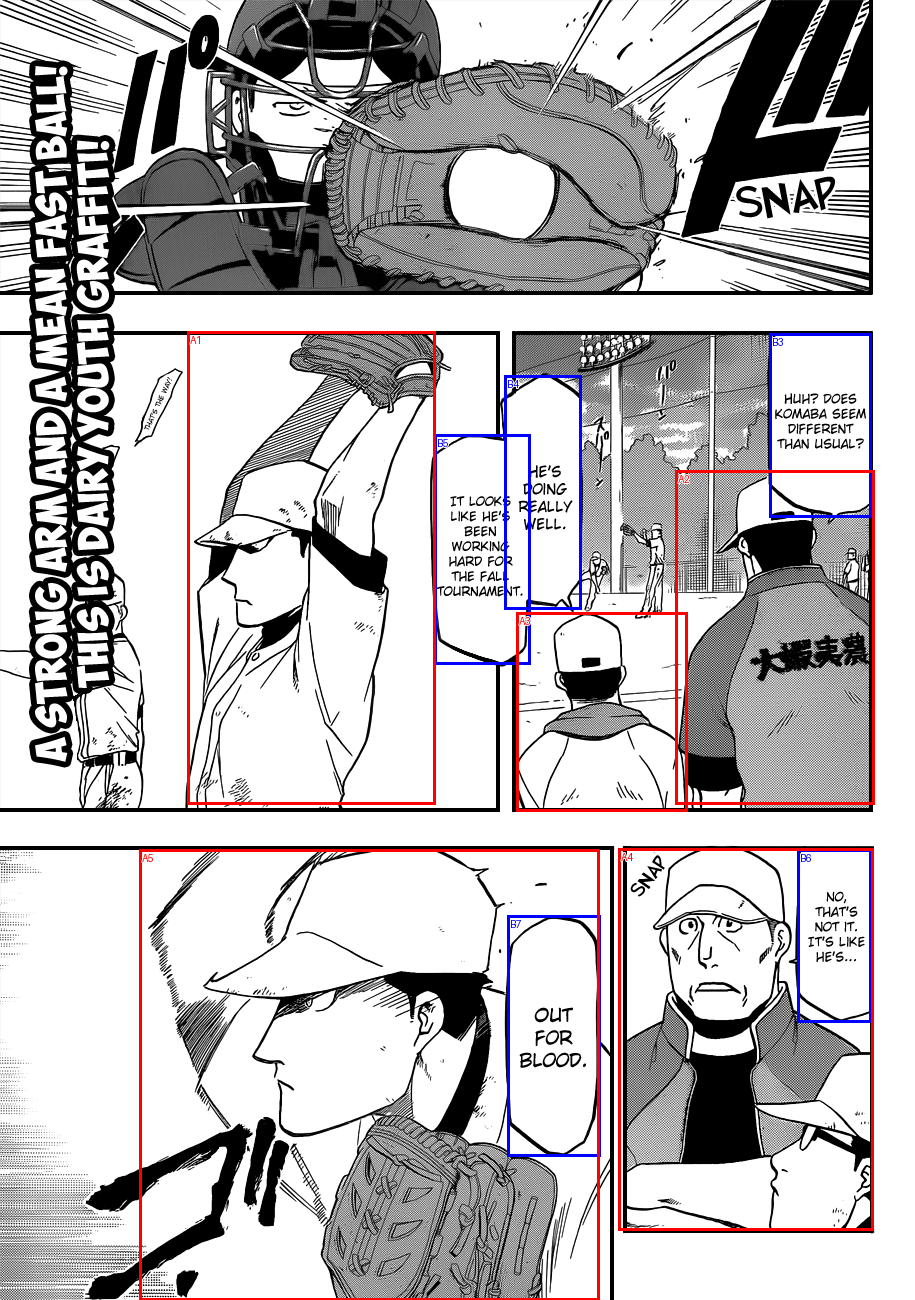


train | seq_2032620aa4e4ac7f | page 2


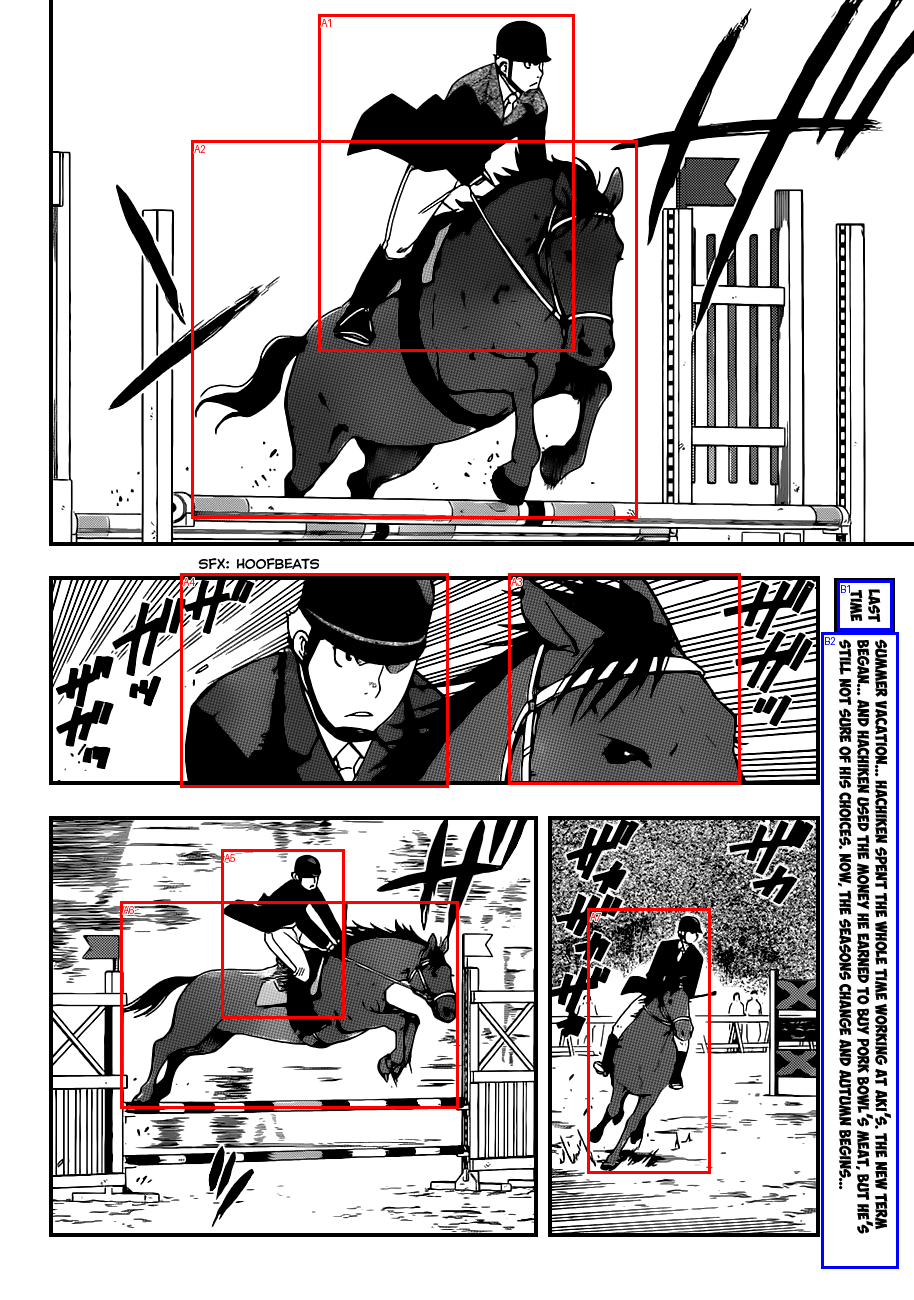


train | seq_2032620aa4e4ac7f | page 3


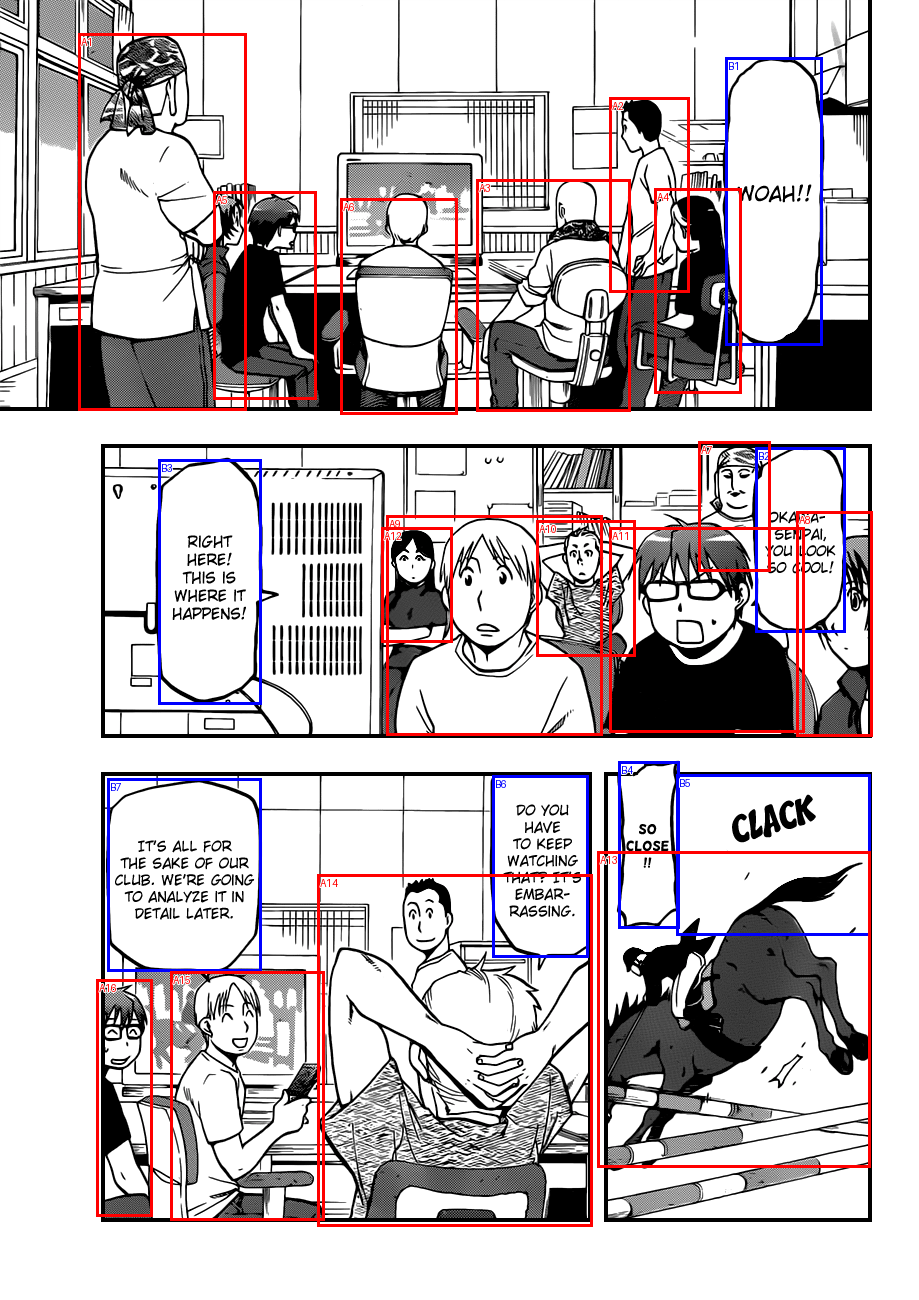

In [5]:
VIEW_SEQUENCE_ID = ""  # Example: "seq_71033fec4de494fc"
sequence_to_view = VIEW_SEQUENCE_ID or (viewed_page["sequence_id"] if viewed_page else "")
if sequence_to_view:
    V.show_sequence(sequence_to_view, VIEW_STAGE, split=VIEW_SPLIT, run_folder=VIEW_RUN)
else:
    print("Set VIEW_SEQUENCE_ID to a sequence in VIEW_SPLIT.")
